# 07 · Mecanismos: cada factor con su propio reloj

## Pregunta y por qué importa

El cuaderno 06 correlacionó cada factor externo con el residuo semanal del triage después de quitar la estacionalidad. Ese diseño borra justo lo que interesa: los efectos que llegan en fechas concretas, con rezagos distintos y sobre subgrupos distintos de pacientes. Un factor que actúa tres días al año, o solo sobre los niños, o solo en día laboral, desaparece en un promedio anual del total. Este cuaderno repite la pregunta con otro método: para cada mecanismo se fija de antemano su reloj (días o semanas), su gatillo (el cambio, no el nivel), su condición (día laboral, fin de semana) y su subgrupo (hora, edad, asegurador), y se mide en episodios concretos.

El orden es el siguiente.

1. La demanda por asegurador: la red de salud como factor.
2. La anatomía de los días pico: cómo son y qué ocurrió antes.
3. Efectos rápidos (0-5 días): la Feria de Manizales frente a otros regresos de vacaciones, la lluvia fuerte frente a los accidentes de tránsito y la relación entre el tránsito de la ciudad y el SOAT del SES.
4. Efectos lentos (1-4 semanas): cambios bruscos de clima y subidas de la infección respiratoria aguda (IRA) de la ciudad, separando día laboral de fin de semana.
5. La red: la caída de Nueva EPS y sus escalones.

## Reglas del análisis

- Las ventanas y los comparadores se fijaron antes de mirar los resultados. Cada prueba declara lo que ya se había visto.
- No se usa el motivo de consulta: las huellas son la hora, la edad y el asegurador.
- El SOAT es el seguro obligatorio de accidentes de tránsito, de modo que su serie mide los accidentes que llegan al SES; la ARL mide los accidentes laborales; «particular» es quien llega sin asegurador.
- Los efectos se expresan en porcentaje sobre lo esperado para ese día de la semana, festivo y año (el control de calendario de la segunda celda de código).
- Cada resultado lleva su intervalo y el número de episodios. Con pocos episodios, lo que sale es una pista y no una prueba.


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})

FIN, INI = "2026-09-20", "2022-03-01"
COVID = ("2020-03-15", "2022-02-28")
dias = pd.date_range("2020-01-01", FIN)

tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
tri = tri.set_index("dia")["triages"].reindex(dias).astype(float)          # dia sin filas = nulo
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
madrugada = hor[hor.hora < 6].groupby("dia")["triages"].sum().reindex(dias).fillna(0)
edad = (pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
          .pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0))
ent = clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
grp = ent.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0)

CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio",
       "es_regreso_colegio"]
calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
cal = calc[CAL + ["dia_semana", "es_no_laboral", "es_habil"]].apply(pd.to_numeric, errors="coerce").fillna(0).reindex(dias)
clima = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
desastres = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
SES = 170010010301

seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
S = pd.DataFrame({"total": tri, "madrugada": madrugada, "transito_ciudad": seg["lesiones_transito"],
                  "0-4": edad.get("0-4", 0), "5-14": edad.get("5-14", 0), "15-44": edad.get("15-44", 0),
                  "65+": edad.get("65-+", 0)}).join(grp)
print(f"{int(tri.sum()):,} triages; grupos: {sorted(grp.columns)}")


433,298 triages; grupos: ['adres_fosyga', 'arl', 'ente_territorial', 'ips_remitente', 'nueva_eps', 'nueva_eps_complementario', 'otra_eps', 'otro', 'particular', 'prepagada', 'regimen_especial', 'sin_entidad', 'soat_aseguradora', 'sura_eps']


In [2]:
# ---------- el control: dia de la semana, festivos y nivel de cada anio (NO la estacionalidad)
Zd = pd.concat([pd.get_dummies(cal["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float),
                cal[CAL], pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)], axis=1)
Zd.insert(0, "c", 1.0)
fuera_covid = ~dias.to_series().between(*COVID).values

def residuo(y, excluir=None):
    """log(y) contra el control, ajustado fuera de COVID. Devuelve % sobre lo esperado (en log)."""
    ly = np.log(y + 0.5)
    ok = fuera_covid & y.notna().values & (True if excluir is None else ~excluir.values)
    b, *_ = np.linalg.lstsq(Zd.values[ok], ly.values[ok], rcond=None)
    r = ly - Zd.values @ b
    return r.where(y.notna())

R = pd.DataFrame(index=dias)
R["total"] = residuo(S.total)
caidos = R.total.lt(np.log(.4)) & fuera_covid       # caidas de registro, ver cuaderno 06
R["total"] = residuo(S.total.where(~caidos))
for c in ["madrugada", "0-4", "15-44", "65+", "nueva_eps", "sura_eps", "soat_aseguradora", "particular", "arl"]:
    R[c] = residuo(S[c].where(~caidos & S.total.notna()))
R["transito_ciudad"] = residuo(S["transito_ciudad"])          # Policia/MinDefensa, toda la ciudad
# Nivel local: MEDIANA del residuo en los 14 dias antes y despues. Los picos se miden contra el,
# no contra la media del anio: un escalon de nivel (Nueva EPS, nov-2025 y mar-2026) no debe
# fabricar ni tapar picos. Centrado porque esto DESCRIBE; el pronostico usara el estado de
# Nueva EPS como variable (un nivel solo hacia atras confunde la recuperacion con un pico).
R["total_local"] = R.total - R.total.rolling(29, center=True, min_periods=20).median()
laboral = (cal.es_habil == 1)
pct = lambda x: (np.exp(x) - 1) * 100
V = R.loc[INI:FIN]
print("caidas de registro excluidas:", [f"{d:%Y-%m-%d}" for d in caidos[caidos].index])
print(f"sd residuo diario del total 2022-2026: {V.total.std():.3f}")


caidas de registro excluidas: ['2024-03-21']
sd residuo diario del total 2022-2026: 0.120


---
# 1. La demanda por asegurador

La figura muestra los triages por día (media mensual) de los grandes grupos de asegurador, con las fechas de intervención y de cierre de servicios a Nueva EPS en la red de Manizales.

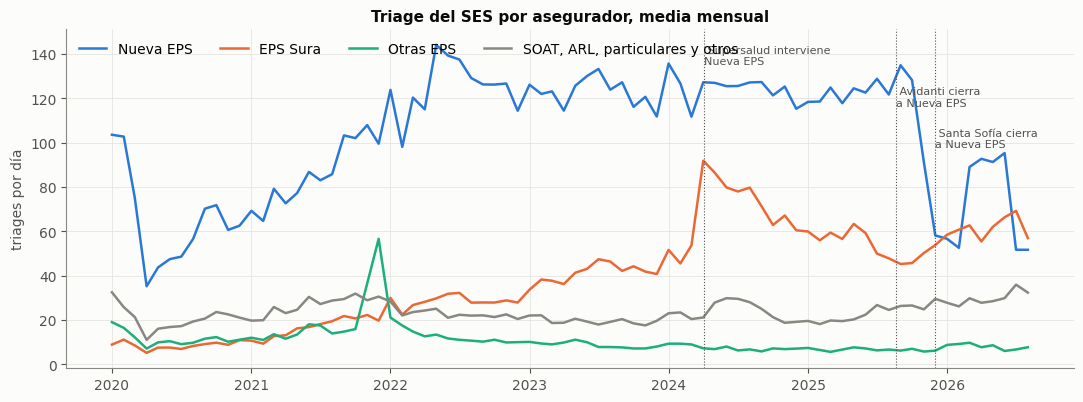

,total,nueva_eps,sura_eps,otra_eps,% Nueva EPS
2020,105.7,64.8,8.6,11.6,61.3
2021,149.3,86.1,16.8,19.7,57.7
2022,189.6,125.3,28.5,12.8,66.1
2023,192.4,122.9,41.1,8.8,63.9
2024,226.4,124.6,69.1,7.5,55.0
2025,199.6,115.8,53.9,6.6,58.0
2026,172.6,72.2,62.0,8.0,41.8


In [3]:
M = S[["nueva_eps", "sura_eps", "otra_eps"]].assign(resto=S.total - S[["nueva_eps", "sura_eps", "otra_eps"]].sum(axis=1))
M = M.loc[:"2026-08-31"].resample("MS").mean()
fig, ax = plt.subplots(figsize=(13, 4.4))
for c, col, nom in [("nueva_eps", AZUL, "Nueva EPS"), ("sura_eps", NARANJA, "EPS Sura"),
                    ("otra_eps", AQUA, "Otras EPS"), ("resto", MUDO, "SOAT, ARL, particulares y otros")]:
    ax.plot(M.index, M[c], color=col, lw=1.8, label=nom)
for i, (f, t) in enumerate([("2024-04-03", "Supersalud interviene\nNueva EPS"), ("2025-08-21", "Avidanti cierra\na Nueva EPS"),
             ("2025-12-01", "Santa Sofía cierra\na Nueva EPS")]):
    ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":"); ax.text(pd.Timestamp(f), M.values.max() * (1.0 - .13 * i), " " + t, fontsize=8, color=TINTA2, va="top")
ax.set_ylabel("triages por día"); ax.set_title("Triage del SES por asegurador, media mensual")
ax.legend(loc="upper left", ncol=4); plt.show()
anual = S[["total", "nueva_eps", "sura_eps", "otra_eps"]].loc[:FIN].groupby(S.loc[:FIN].index.year).mean().round(1)
anual["% Nueva EPS"] = (100 * anual.nueva_eps / anual.total).round(1)
anual


In [4]:
# Otras EPS: media mensual de triages por dia alrededor del pico de finales de 2021
print(S["otra_eps"].loc["2021-09":"2022-02"].resample("MS").mean().round(1).rename(lambda d: f"{d:%Y-%m}").to_string())

2021-09    14.8
2021-10    15.9
2021-11    36.5
2021-12    56.6
2022-01    21.1
2022-02    17.5


## Lectura

**La demanda del SES es, sobre todo, demanda de Nueva EPS, y es la que se mueve.**

| | 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|---|
| Total por día | 105,7 | 149,3 | 189,6 | 192,4 | 226,4 | 199,6 | 172,6 |
| Nueva EPS | 64,8 | 86,1 | 125,3 | 122,9 | 124,6 | 115,8 | **72,2** |
| EPS Sura | 8,6 | 16,8 | 28,5 | 41,1 | 69,1 | 53,9 | 62,0 |
| % Nueva EPS | 61 | 58 | 66 | 64 | 55 | 58 | **42** |

La caída de 2026 es de Nueva EPS: pasa de 115,8 a 72,2 triages por día (−38 %) mientras Sura sube. Buena parte de lo que parece «el hospital recibe menos gente» es «el hospital recibe menos afiliados de una EPS».

Los cambios de nivel son escalones y no tendencias. Sura salta en abril de 2024, el mes en que la Supersalud interviene Nueva EPS; el escalón fue de Sura, no de Nueva EPS. Nueva EPS se hunde a mediados de noviembre de 2025 y de nuevo en julio de 2026 (sección 5). Las otras EPS tienen un pico de dos meses a finales de 2021 (de 15,9 triages por día en octubre a 56,6 en diciembre, y 21,1 en enero de 2022), que es un episodio y no un escalón; su causa no se identificó con los datos disponibles.

El asegurador es, por tanto, un factor externo de primer orden. Es institucional y no clínico, y por eso ningún calendario lo recogía.

**Límite.** La clasificación de entidades es automática por nombre, no una tabla oficial. Nueva EPS tiene dos códigos en la base y se suman. El máximo de 2024 no se explica con esta figura: de 2024 a 2025 la caída es sobre todo del resto de aseguradores y no de Nueva EPS.


---
# 2. Anatomía de los días pico

Se llama día pico al que queda más de 2 desviaciones por encima de lo esperado (2022-03 a 2026-09). No es una prueba sino una mirada de cerca a los días que se quiere poder anticipar. Se hacen dos preguntas. **(a)** Cuál es su huella: cuánto pesa cada subgrupo en un pico frente a un día normal del mismo día de la semana y año. **(b)** Qué pasó antes: con qué frecuencia cada antecedente precede a un pico frente a un día cualquiera.

In [5]:
sd = V.total_local.std()
pico = V.total_local > 2 * sd
pico_anual = V.total > 2 * V.total.std()
print(f"{int(pico.sum())} días pico contra el nivel local (umbral +{pct(2*sd):.0f} %); "
      f"contra la media del año eran {int(pico_anual.sum())}; coinciden {int((pico & pico_anual).sum())}")
print("picos que solo aparecen contra el nivel local:", [f"{d:%Y-%m-%d}" for d in pico[pico & ~pico_anual].index])

# (a) huella: cuota de cada subgrupo en el pico / cuota en dias normales del mismo dia de la semana y anio
cuota = pd.DataFrame({c: S[c] / S.total for c in ["madrugada", "0-4", "15-44", "65+", "soat_aseguradora", "particular", "arl", "nueva_eps"]}).loc[V.index]
clave = pd.Series(list(zip(V.index.dayofweek, V.index.year)), index=V.index)
normal = cuota[~pico & V.total_local.notna()].groupby(clave[~pico & V.total_local.notna()]).mean()
esperada = normal.reindex(pd.MultiIndex.from_tuples(clave[pico].tolist())).set_axis(clave[pico].index)
huella = (cuota[pico] / esperada)
tabla_h = pd.DataFrame({"cuota normal %": (100 * normal.mean()).round(2),
                        "cuota en picos %": (100 * cuota[pico].mean()).round(2),
                        "razón pico/normal": huella.mean().round(2),
                        "IC95 bajo": (huella.mean() - 1.96 * huella.std() / np.sqrt(len(huella))).round(2),
                        "IC95 alto": (huella.mean() + 1.96 * huella.std() / np.sqrt(len(huella))).round(2)})
tabla_h.index = ["madrugada 0-5 h", "0-4 años", "15-44 años", "65+ años", "SOAT (tránsito)", "particular", "ARL (laboral)", "Nueva EPS"]
display(tabla_h)
print("días pico por día de la semana:", pico[pico].index.day_name().value_counts().to_dict())
print("días pico por mes:", pico[pico].index.month.value_counts().sort_index().to_dict())


30 días pico contra el nivel local (umbral +22 %); contra la media del año eran 22; coinciden 17
picos que solo aparecen contra el nivel local: ['2022-12-25', '2023-04-13', '2023-11-16', '2024-01-18', '2024-02-17', '2024-04-11', '2025-12-10', '2025-12-26', '2025-12-27', '2026-01-04', '2026-01-17', '2026-02-07', '2026-02-15']


,cuota normal %,cuota en picos %,razón pico/normal,IC95 bajo,IC95 alto
madrugada 0-5 h,6.78,7.88,1.02,0.93,1.10
0-4 años,3.45,3.70,0.95,0.79,1.10
15-44 años,53.31,53.17,1.03,1.01,1.06
65+ años,19.92,20.23,0.97,0.91,1.02
SOAT (tránsito),3.82,3.79,1.03,0.80,1.27
particular,0.79,0.81,1.13,0.74,1.52
ARL (laboral),0.97,1.20,1.30,0.88,1.71
Nueva EPS,56.73,53.19,0.99,0.94,1.03


días pico por día de la semana: {'Sunday': 10, 'Saturday': 8, 'Thursday': 6, 'Wednesday': 3, 'Friday': 2, 'Monday': 1}
días pico por mes: {1: 9, 2: 3, 4: 3, 5: 4, 7: 2, 8: 2, 11: 1, 12: 6}


In [6]:
# (b) antecedentes: que paso antes de cada pico, contra la tasa base de cualquier dia
def banda_dias(fechas_ini, fechas_fin=None):
    s = pd.Series(False, index=dias)
    fechas_fin = fechas_ini if fechas_fin is None else fechas_fin
    for a, b in zip(fechas_ini, fechas_fin):
        s.loc[pd.Timestamp(a):pd.Timestamp(b)] = True
    return s
ok_ev = eventos.estado.isin(["realizado", "hibrido"]) & eventos.fecha_inicio.notna()
ev = eventos[ok_ev]
dia_evento = banda_dias(ev.fecha_inicio, ev.fecha_fin.fillna(ev.fecha_inicio))
dia_feria = banda_dias(*[ev[ev.nombre_evento.eq("Feria de Manizales")][c] for c in ("fecha_inicio", "fecha_fin")])
bloque = cal.es_no_laboral.eq(1)
largo = bloque.groupby((~bloque).cumsum()).transform("sum").where(bloque, 0)
regreso = (~bloque) & bloque.shift(1, fill_value=False) & largo.shift(1).fillna(0).ge(3)

# clima: lluvia fuerte (solo con pluviometro) y transiciones
p = clima.precip_consenso_mm.where(clima.precip_con_estacion.astype(float) == 1)
p90 = p.groupby(p.index.month).transform(lambda s: s.quantile(.9))
lluvia_fuerte = (p >= p90) & p.notna() & (p > 1)
t = clima.temp_media_consenso
dT = t.rolling(7).mean() - t.shift(7).rolling(21).mean()
zT = (dT - dT.groupby(dT.index.month).transform("mean")) / dT.groupby(dT.index.month).transform("std")
pr = clima.precip_consenso_mm
p7, p21 = pr.rolling(7).sum(), pr.shift(7).rolling(21).sum() / 3
z7 = (p7 - p7.groupby(p7.index.month).transform("mean")) / p7.groupby(p7.index.month).transform("std")
z21 = (p21 - p21.groupby(p21.index.month).transform("mean")) / p21.groupby(p21.index.month).transform("std")
seco_a_lluvioso = (z7 >= 1) & (z21 <= -.5)
calentamiento, enfriamiento = zT >= 1, zT <= -1

# IRA de la ciudad sin el SES: subida fuerte a 2 semanas
ira = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum()
cambio = np.log(ira.replace(0, np.nan)).diff(2)
subida_sem = cambio > cambio.loc["2022":].quantile(.8)
ira_subida = pd.Series(False, index=dias)
for s0 in subida_sem[subida_sem].index:
    ira_subida.loc[s0:s0 + pd.Timedelta(days=6)] = True
d_ok = desastres[desastres.ambito.isin(["municipal", "institucional"]) & ~desastres.calidad_dato.isin(["pendiente_verificacion"])]
dia_desastre = banda_dias(d_ok.fecha_inicio, d_ok.fecha_fin)

def antes(senal, desde, hasta):
    """True si la senal ocurrio entre 'desde' y 'hasta' dias antes (inclusive)."""
    s = senal.astype(float)
    return s.shift(desde).rolling(hasta - desde + 1, min_periods=1).max().fillna(0).astype(bool)

ANT = {"evento social, 0-5 días antes": antes(dia_evento, 0, 5),
       "Feria, 0-5 días antes": antes(dia_feria, 0, 5),
       "regreso de bloque no laboral (≥3 días), 0-2 días antes": antes(regreso, 0, 2),
       "lluvia fuerte, 0-1 días antes": antes(lluvia_fuerte, 0, 1),
       "calentamiento brusco, 7-28 días antes": antes(calentamiento, 7, 28),
       "enfriamiento brusco, 7-28 días antes": antes(enfriamiento, 7, 28),
       "paso de seco a lluvioso, 7-28 días antes": antes(seco_a_lluvioso, 7, 28),
       "subida fuerte de IRA en la ciudad, 7-21 días antes": antes(ira_subida, 7, 21),
       "desastre, 0-14 días antes": antes(dia_desastre, 0, 14)}
base_ok = V.total_local.notna()
filas = []
for k, s in ANT.items():
    s = s.reindex(V.index)
    a, b = s[pico].mean(), s[base_ok & ~pico].mean()
    filas.append({"antecedente": k, "% de picos": round(100 * a, 1), "% de días normales": round(100 * b, 1),
                  "razón": round(a / b, 2) if b else np.nan, "picos con él": int(s[pico].sum())})
tabla_a = pd.DataFrame(filas).set_index("antecedente").sort_values("razón", ascending=False)
tabla_a


,% de picos,% de días normales,razón,picos con él
antecedente,,,,
"Feria, 0-5 días antes",16.7,3.1,5.32,5
"evento social, 0-5 días antes",60.0,29.8,2.01,18
"regreso de bloque no laboral (≥3 días), 0-2 días antes",16.7,10.8,1.55,5
"enfriamiento brusco, 7-28 días antes",80.0,65.3,1.22,24
"subida fuerte de IRA en la ciudad, 7-21 días antes",43.3,37.9,1.14,13
"calentamiento brusco, 7-28 días antes",70.0,68.5,1.02,21
"lluvia fuerte, 0-1 días antes",6.7,8.5,0.79,2
"paso de seco a lluvioso, 7-28 días antes",20.0,29.4,0.68,6
"desastre, 0-14 días antes",0.0,5.7,0.00,0


## Lectura

**Definición de pico.** Un día es pico si queda más de 2 desviaciones por encima de su nivel local, la mediana de los 14 días anteriores y posteriores. No se compara con la media del año porque, en un año partido por el desplome de Nueva EPS, eso fabrica picos donde solo hay un escalón y esconde otros. El nivel lo mueve la red; los picos, otras cosas. Con esta definición hay 30 picos; contra la media del año eran 22, y coinciden 17.

**(a) Los picos no son un subgrupo distinto: son «más de todo».** Su composición por hora, edad y asegurador es casi la de un día normal. Lo único que se aparta algo es la ARL (accidente laboral, razón 1,30) y los particulares (1,13), con intervalos que cruzan 1. De los 30 picos, 18 caen en sábado o domingo, 9 en enero y 6 en diciembre: las temporadas de fiestas.

**(b) Lo que precede a los picos es lo social y lo rápido.** La Feria en los 5 días previos aparece 5,3 veces más que en un día cualquiera (5 de los 30 picos); un evento social en los 5 días previos, 2,0 veces (18 de 30); el regreso de un bloque no laboral, 1,6 veces. El enfriamiento brusco de 1 a 4 semanas antes sale en 1,2 veces (24 de 30 frente al 65 % de los días): es una señal débil porque la ventana es tan ancha que casi todos los días la tienen. Lo lento se mide mejor mirando hacia adelante desde el cambio (sección 4).

**Límite.** Treinta picos son pocos. Cada razón es una pista que hay que confirmar con episodios nuevos, no un hallazgo.


---
# 3. Efectos rápidos (0-5 días)

## 3.1 La Feria frente a otros regresos de vacaciones

La Feria de Manizales arranca siempre al regreso de las vacaciones de fin de año, así que cualquier subida en esos días podría ser simplemente el regreso. Para separar ambas cosas se comparan los días 0 a 4 desde el inicio de la Feria con los días 0 a 4 tras el fin de cualquier otro bloque no laboral de 3 días o más (fuera de diciembre y enero; 52 episodios). Si la subida es de la Feria y no del regreso, la Feria debe subir más y tener otra huella: más 15-44, más SOAT, más particulares y más madrugada.

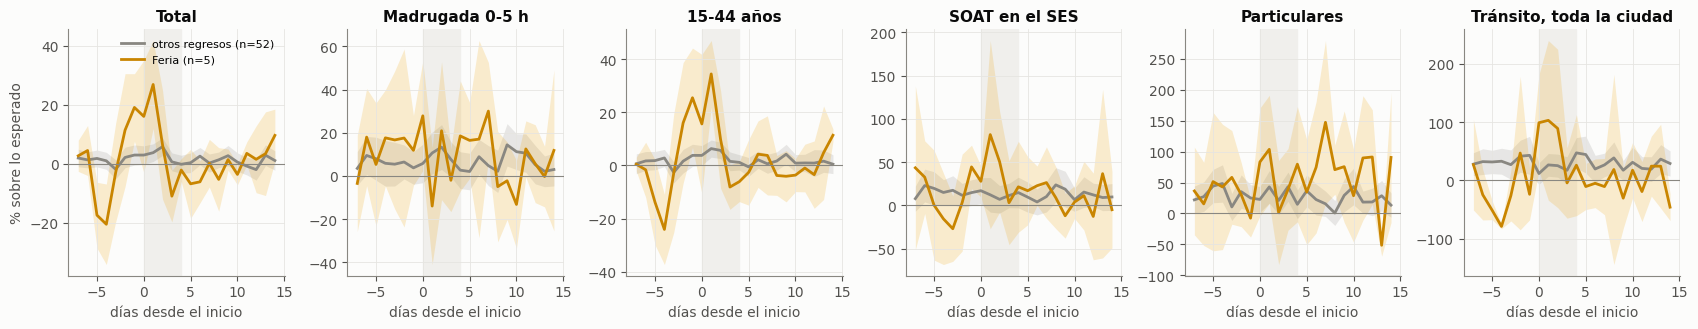

media días 0-4 (%)  ± IC95  episodios
total            otros regresos                 2.7     2.3       52.0
                 Feria                          7.3     8.5        5.0
madrugada        otros regresos                 8.0     5.1       52.0
                 Feria                         10.2     3.9        5.0
15-44            otros regresos                 3.7     2.2       52.0
                 Feria                          9.1     7.6        5.0
soat_aseguradora otros regresos                12.5     8.5       52.0
                 Feria                         36.9     5.5        5.0
particular       otros regresos                28.9    10.4       52.0
                 Feria                         61.3    34.4        5.0
transito_ciudad  otros regresos                25.8    10.6       52.0
                 Feria                         62.7    50.8        5.0

In [7]:
ferias = pd.to_datetime(ev[ev.nombre_evento.eq("Feria de Manizales")].fecha_inicio)
ferias = [f for f in ferias if f >= pd.Timestamp("2020-01-01") and not (pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1]))]
regresos = [d for d in regreso[regreso].index if d.month not in (12, 1) and not (pd.Timestamp(COVID[0]) <= d <= pd.Timestamp(COVID[1]))
            and d <= pd.Timestamp(FIN) - pd.Timedelta(days=14)]
def curva(serie, fechas, k=range(-7, 15)):
    return pd.DataFrame({f: serie.reindex([f + pd.Timedelta(days=i) for i in k]).values for f in fechas}, index=list(k))
cols = ["total", "madrugada", "15-44", "soat_aseguradora", "particular", "transito_ciudad"]
resumen = {}
fig, axes = plt.subplots(1, len(cols), figsize=(17, 3.4), sharex=True)
for ax, c in zip(axes, cols):
    for fechas, col, nom in [(regresos, MUDO, f"otros regresos (n={len(regresos)})"), (ferias, AMARILLO, f"Feria (n={len(ferias)})")]:
        cu = pct(curva(R[c], fechas)); m = cu.mean(axis=1); e = 1.96 * cu.std(axis=1) / np.sqrt(cu.notna().sum(axis=1))
        ax.fill_between(m.index, m - e, m + e, color=col, alpha=.18, lw=0); ax.plot(m.index, m, color=col if col != AMARILLO else "#c98500", lw=2, label=nom)
        v = cu.loc[0:4].mean()                     # media de los dias 0-4 de cada episodio
        resumen[(c, nom.split(" (")[0])] = (v.mean(), 1.96 * v.std() / np.sqrt(v.notna().sum()), v.notna().sum())
    ax.axvspan(0, 4, color="#f0efec", zorder=0); ax.axhline(0, color=MUDO, lw=.8)
    ax.set_title({"total": "Total", "madrugada": "Madrugada 0-5 h", "15-44": "15-44 años",
                  "soat_aseguradora": "SOAT en el SES", "particular": "Particulares",
                  "transito_ciudad": "Tránsito, toda la ciudad"}[c])
    ax.set_xlabel("días desde el inicio")
axes[0].set_ylabel("% sobre lo esperado"); axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()
out = pd.DataFrame(resumen, index=["media días 0-4 (%)", "± IC95", "episodios"]).T.round(1)
out


## Lectura

**La Feria tiene una huella propia en los accidentes y en quien llega sin su asegurador de siempre.** Media de los días 0 a 4, en porcentaje sobre lo esperado:

| | Otros regresos (n = 52) | Feria (n = 5) |
|---|---|---|
| Total | +2,7 ± 2,3 | +7,3 ± 8,5 |
| Madrugada 0-5 h | +8,0 ± 5,1 | +10,2 ± 3,9 |
| 15-44 años | +3,7 ± 2,2 | +9,1 ± 7,6 |
| **SOAT (tránsito)** | +12,5 ± 8,5 | **+36,9 ± 5,5** |
| Particulares | +28,9 ± 10,4 | +61,3 ± 34,4 |
| Tránsito en toda la ciudad (Policía) | +25,8 ± 10,6 | +62,7 ± 50,8 |

- Los accidentes de tránsito atendidos casi se triplican respecto de un regreso normal (+36,9 frente a +12,5). Es la diferencia más limpia, y sigue separada si se ensancha el intervalo para tener solo 5 Ferias (distribución t de Student con 4 grados de libertad: ±7,8).
- Los particulares suben 61 % frente a 29 %, pero con 5 Ferias el intervalo es ancho y se solapa.
- En el total la Feria sube +7,3 y los otros regresos +2,7, y los intervalos se solapan: sobre el volumen completo la diferencia no se distingue.
- La madrugada de la Feria (+10,2) no se separa de la de otros regresos (+8,0), de modo que la expectativa de una huella nocturna propia no se confirma con este diseño.
- El tránsito de toda la ciudad sube también en la Feria, pero con un intervalo muy ancho: ese promedio lo arrastra la Feria de 2020 (+163 %), y en los demás años se parece a un regreso normal. Por eso la serie de la ciudad no se toma como evidencia adicional.
- Una parte de la subida empieza 2 o 3 días antes de la Feria, el 1 y 2 de enero. Una fracción del efecto es Año Nuevo, y con 5 años no se puede separar del todo.

El resultado tiene la forma esperada de un mecanismo de exposición (trasnocho, trago, tránsito, visitantes), y se ve sin leer ningún motivo de consulta. La sección siguiente lo descompone por asegurador y por hora.

### La firma de la Feria por asegurador y por franja horaria

Se repite la misma comparación (días 0 a 4, 5 Ferias frente a 52 regresos) separando el triage por grupo de asegurador y por franja horaria. Si la Feria trae a quien está de paso, el exceso debe concentrarse en quienes no tienen a Nueva EPS ni a Sura como asegurador, y en horas de actividad social.

,otros regresos,Feria,± IC95 con t (Feria)
serie,,,
Nueva EPS,+2.8 ± 4.5,+14.4 ± 7.9,11.2
EPS Sura,+7.0 ± 3.3,-4.2 ± 20.5,29.1
Otras EPS,+11.1 ± 5.2,+32.0 ± 6.3,9.0
SOAT,+12.5 ± 8.5,+36.9 ± 5.5,7.8
Particulares,+28.9 ± 10.4,+61.3 ± 34.4,48.8
ARL,+24.8 ± 10.4,+34.9 ± 34.7,49.1
IPS remitente,+22.6 ± 13.2,+16.8 ± 33.5,47.5
Régimen especial,+25.7 ± 9.6,-6.4 ± 22.2,31.5
0-5 h,+8.0 ± 5.1,+10.2 ± 3.9,5.5


,2020,2023,2024,2025,2026
"Feria (media días 0-4, %)",,,,,
Nueva EPS,14.0,11.0,8.0,30.0,10.0
EPS Sura,24.0,-22.0,-33.0,13.0,-3.0
Otras EPS,25.0,33.0,43.0,32.0,26.0
SOAT,37.0,39.0,45.0,28.0,35.0
Particulares,115.0,73.0,8.0,44.0,66.0
ARL,42.0,45.0,37.0,-29.0,80.0
IPS remitente,35.0,-23.0,-19.0,69.0,22.0
Régimen especial,22.0,-3.0,-45.0,-13.0,7.0
0-5 h,11.0,5.0,14.0,15.0,6.0


SOAT + otras EPS + particulares: 9.0 % del triage 2022-2026


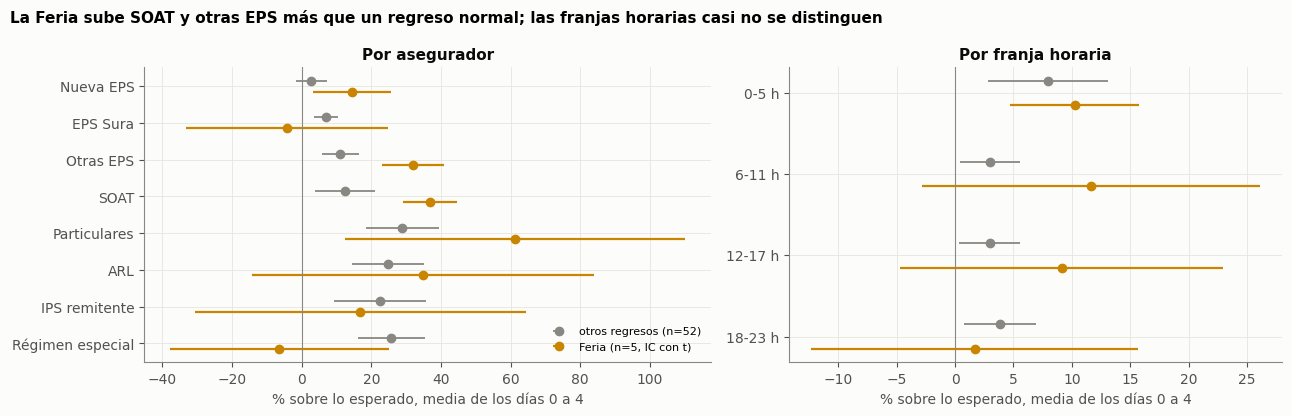

In [8]:
from scipy import stats
# Residuo (misma regresion de calendario y anio) por grupo de asegurador y por franja horaria
base_ok = ~caidos & S.total.notna()
RG = pd.DataFrame(index=dias)
GRUPOS = {"nueva_eps": "Nueva EPS", "sura_eps": "EPS Sura", "otra_eps": "Otras EPS", "soat_aseguradora": "SOAT",
          "particular": "Particulares", "arl": "ARL", "ips_remitente": "IPS remitente",
          "regimen_especial": "Régimen especial"}
for g in GRUPOS:
    RG[g] = residuo(grp[g].where(base_ok))
FRANJAS = {"0-5 h": (0, 5), "6-11 h": (6, 11), "12-17 h": (12, 17), "18-23 h": (18, 23)}
for nom, (a, b) in FRANJAS.items():
    y = hor[(hor.hora >= a) & (hor.hora <= b)].groupby("dia")["triages"].sum().reindex(dias).fillna(0)
    RG[nom] = residuo(y.where(base_ok))

def resumen_ep(serie, fechas):
    v = pct(curva(serie, fechas)).loc[0:4].mean()          # media de los dias 0-4 de cada episodio
    n = int(v.notna().sum()); se = v.std() / np.sqrt(n)
    return v, v.mean(), 1.96 * se, stats.t.ppf(.975, n - 1) * se

filas, por_feria = [], {}
for col in list(GRUPOS) + list(FRANJAS):
    vo, mo, eo, _ = resumen_ep(RG[col], regresos)
    vf, mf, ef, ef_t = resumen_ep(RG[col], ferias)
    nom = GRUPOS.get(col, col)
    filas.append({"serie": nom, "otros regresos": f"{mo:+.1f} ± {eo:.1f}", "Feria": f"{mf:+.1f} ± {ef:.1f}",
                  "± IC95 con t (Feria)": round(ef_t, 1), "m_o": mo, "e_o": eo, "m_f": mf, "e_f": ef_t})
    por_feria[nom] = vf.round(0).values
T31 = pd.DataFrame(filas).set_index("serie")
display(T31[["otros regresos", "Feria", "± IC95 con t (Feria)"]])
display(pd.DataFrame(por_feria, index=[f"{f:%Y}" for f in ferias]).T.rename_axis("Feria (media días 0-4, %)"))

# peso de los tres grupos que concentran el exceso, 2022-2026
peso = (grp[["soat_aseguradora", "otra_eps", "particular"]].sum(axis=1) / S.total).loc[INI:FIN].mean()
print(f"SOAT + otras EPS + particulares: {100 * peso:.1f} % del triage 2022-2026")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, nombres, tit in [(axes[0], list(GRUPOS.values()), "Por asegurador"), (axes[1], list(FRANJAS), "Por franja horaria")]:
    t = T31.loc[nombres]; y = np.arange(len(t))
    ax.errorbar(t.m_o, y - .15, xerr=1.96 * t.e_o / 1.96, fmt="o", color=MUDO, ms=6, lw=1.3, label="otros regresos (n=52)")
    ax.errorbar(t.m_f, y + .15, xerr=t.e_f, fmt="o", color="#c98500", ms=6, lw=1.6, label="Feria (n=5, IC con t)")
    ax.axvline(0, color=MUDO, lw=.8); ax.set_yticks(y, nombres); ax.invert_yaxis()
    ax.set_xlabel("% sobre lo esperado, media de los días 0 a 4"); ax.set_title(tit)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("La Feria sube SOAT y otras EPS más que un regreso normal; las franjas horarias casi no se distinguen", fontsize=11, fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()


**Lectura.**

El exceso de la Feria se concentra en tres grupos pequeños: SOAT (+36,9 %), otras EPS distintas de Nueva EPS y Sura (+32,0 % frente a +11,1 %) y particulares (+61,3 %). Los dos primeros tienen intervalos estrechos y suben en cada una de las 5 Ferias (SOAT entre +28 y +45 %, otras EPS entre +25 y +43 %), de modo que no depende de un año atípico. Nueva EPS sube de forma moderada (+14,4 %) y Sura no se mueve (−4,2 ± 20,5). Los particulares varían mucho entre años (de +8 a +115 %), y el régimen especial, que sube +25,7 % en otros regresos, no sube en la Feria. Esa composición es coherente con visitantes y gente de paso, que llegan con un asegurador de otra ciudad o sin ninguno, y con los accidentes del fin de las vacaciones.

Esos tres grupos suman solo alrededor del 9,0 % del triage, y eso explica por qué el total apenas sube (+7,3 %): un efecto grande sobre una fracción pequeña del volumen queda diluido en el conjunto, que es el argumento por el que se mide por subgrupo.

Por franja horaria, el exceso de la Feria aparece en las horas de actividad (6-11 h, +11,6; 12-17 h, +9,2), pero con intervalos anchos que se solapan con los de otros regresos, y no aparece en la noche temprana (18-23 h, +1,7). La madrugada no se distingue de un regreso normal. La franja horaria aporta, por tanto, poca evidencia diferencial.

**Límite.** El mecanismo «llegan al SES porque son tantos» (por saturación de otras clínicas o por remisiones desde otros municipios) no está probado. Lo que los datos muestran es que quien llega en la Feria tiene un perfil de asegurador distinto; no muestran por qué llega al SES y no a otra institución. Para contrastarlo se necesitarían las remisiones diarias del Centro Regulador de Urgencias y Emergencias (CRUE) y la ocupación de las clínicas de la ciudad, que no están disponibles a escala diaria. Además, el grupo «IPS remitente» no separa nada (+16,8 ± 33,5 en la Feria frente a +22,6 ± 13,2 en otros regresos), y solo hay 5 Ferias, una de ellas en 2020.

## 3.2 Lluvia fuerte y accidentes de tránsito

Se define lluvia fuerte como un día en el 10 % más lluvioso de su mes, usando solo días con pluviómetro válido. Se mide el efecto sobre el SOAT el mismo día y el siguiente, y sobre el total y la madrugada el mismo día.

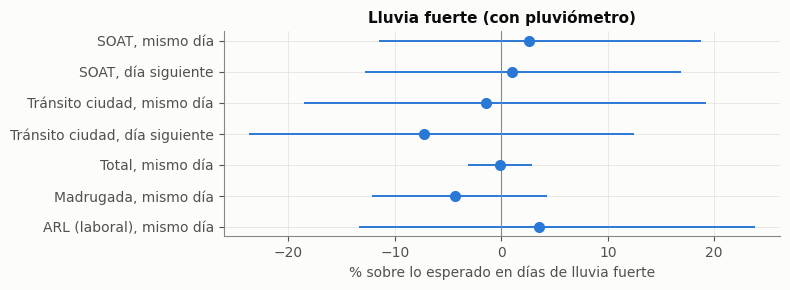

,efecto %,IC95 bajo,IC95 alto,días con lluvia fuerte,días sin
desenlace,,,,,
"SOAT, mismo día",2.6,-11.5,18.8,79,616
"SOAT, día siguiente",1.0,-12.8,16.9,73,622
"Tránsito ciudad, mismo día",-1.4,-18.5,19.2,79,616
"Tránsito ciudad, día siguiente",-7.3,-23.7,12.5,73,622
"Total, mismo día",-0.1,-3.1,2.9,79,616
"Madrugada, mismo día",-4.3,-12.1,4.3,79,616
"ARL (laboral), mismo día",3.5,-13.4,23.8,79,616


In [9]:
con_pluv = p.notna() & fuera_covid
filas = []
for nom, serie, lag in [("SOAT, mismo día", "soat_aseguradora", 0), ("SOAT, día siguiente", "soat_aseguradora", 1),
                        ("Tránsito ciudad, mismo día", "transito_ciudad", 0), ("Tránsito ciudad, día siguiente", "transito_ciudad", 1),
                        ("Total, mismo día", "total", 0), ("Madrugada, mismo día", "madrugada", 0),
                        ("ARL (laboral), mismo día", "arl", 0)]:
    x = lluvia_fuerte.shift(lag).fillna(False)[con_pluv & dias.to_series().ge(pd.Timestamp(INI)).values]
    y = R[serie][con_pluv & dias.to_series().ge(pd.Timestamp(INI)).values]; ok = y.notna()
    a, b = y[ok & x], y[ok & ~x]
    d = a.mean() - b.mean(); e = 1.96 * np.sqrt(a.var() / len(a) + b.var() / len(b))
    filas.append({"desenlace": nom, "efecto %": round(pct(d), 1), "IC95 bajo": round(pct(d - e), 1),
                  "IC95 alto": round(pct(d + e), 1), "días con lluvia fuerte": len(a), "días sin": len(b)})
T32 = pd.DataFrame(filas).set_index("desenlace")
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(T32["efecto %"], range(len(T32)), xerr=[T32["efecto %"] - T32["IC95 bajo"], T32["IC95 alto"] - T32["efecto %"]],
            fmt="o", color=AZUL, ms=7, lw=1.4)
ax.axvline(0, color=MUDO, lw=.8); ax.set_yticks(range(len(T32)), T32.index); ax.invert_yaxis()
ax.set_xlabel("% sobre lo esperado en días de lluvia fuerte"); ax.set_title("Lluvia fuerte (con pluviómetro)")
plt.tight_layout(); plt.show()
T32


## Lectura

**La lluvia fuerte no sube los accidentes atendidos, ni en el SES ni en la ciudad.** Los efectos son pequeños y todos los intervalos incluyen el cero:

| Desenlace | Efecto | IC95 |
|---|---|---|
| SOAT, mismo día | +2,6 % | [−11,5; +18,8] |
| SOAT, día siguiente | +1,0 % | [−12,8; +16,9] |
| Tránsito de la ciudad, mismo día | −1,4 % | [−18,5; +19,2] |
| Tránsito de la ciudad, día siguiente | −7,3 % | [−23,7; +12,5] |
| Total, mismo día | −0,1 % | [−3,1; +2,9] |
| Madrugada, mismo día | −4,3 % | [−12,1; +4,3] |
| ARL, mismo día | +3,5 % | [−13,4; +23,8] |

El signo de la madrugada y del tránsito de la ciudad es negativo (llueve y hay algo menos de gente en la calle), pero ninguno se distingue de cero. La lluvia fuerte no mueve el triage del SES en ninguna de sus huellas. Una versión anterior del análisis daba −6,4 % de madrugada; se calculó con un pluviómetro que reportaba cero milímetros días enteros mientras llovía, y con el pluviómetro corregido esa cifra deja de ser distinguible de cero.

**Límite.** Solo 79 días de lluvia fuerte tienen pluviómetro válido desde 2022 (frente a 616 días sin lluvia fuerte), y los intervalos para el SOAT son de ±15 %: un efecto de hasta ese orden no se descarta. La serie de la Policía solo cuenta lo denunciado.

## 3.3 Accidentes de tránsito de la ciudad y SOAT del SES

Se comparan las lesiones en accidente de tránsito registradas por la Policía en toda Manizales (MinDefensa, datos.gov.co) con los triages del SES pagados por SOAT. No se comparan cantidades, porque la Policía solo registra lo que se denuncia y el SOAT del SES incluye accidentes de otros municipios. Se compara si suben y bajan juntos.

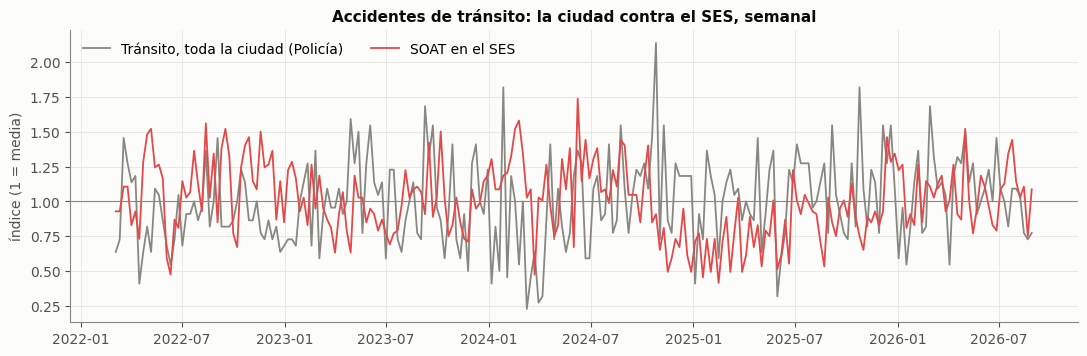

casos por día 2022-2026: ciudad 3.1, SOAT en el SES 7.2
r semanal en conteo:              -0.005
r semanal sin calendario ni año:  +0.011
r diario sin calendario ni año:   +0.013


In [10]:
A = pd.DataFrame({"ciudad": S.transito_ciudad, "SES": S.soat_aseguradora}).loc["2022-03-01":"2026-08-28"]
Aw = A.resample("W-SAT").sum()
Rw = R[["transito_ciudad", "soat_aseguradora"]].loc["2022-03-01":"2026-08-28"].resample("W-SAT").mean()
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(Aw.index, Aw.ciudad / Aw.ciudad.mean(), color=MUDO, lw=1.3, label="Tránsito, toda la ciudad (Policía)")
ax.plot(Aw.index, Aw.SES / Aw.SES.mean(), color=ROJO, lw=1.3, label="SOAT en el SES")
ax.axhline(1, color=MUDO, lw=.8); ax.set_ylabel("índice (1 = media)"); ax.legend(loc="upper left", ncol=2)
ax.set_title("Accidentes de tránsito: la ciudad contra el SES, semanal"); plt.show()
print(f"casos por día 2022-2026: ciudad {A.ciudad.mean():.1f}, SOAT en el SES {A.SES.mean():.1f}")
print(f"r semanal en conteo:              {Aw.ciudad.corr(Aw.SES):+.3f}")
print(f"r semanal sin calendario ni año:  {Rw.transito_ciudad.corr(Rw.soat_aseguradora):+.3f}")
print(f"r diario sin calendario ni año:   {R.transito_ciudad.loc[A.index].corr(R.soat_aseguradora.loc[A.index]):+.3f}")


## Lectura

**No se mueven juntos.** La correlación entre los accidentes de tránsito de la ciudad y el SOAT del SES es de +0,01, tanto por día como por semana, con o sin quitar el calendario.

| | Casos por día (2022-2026) |
|---|---|
| Tránsito, toda la ciudad (Policía) | 3,1 |
| SOAT en el SES | 7,2 |

El SOAT del SES no equivale a «los accidentes de Manizales». Los accidentados de la ciudad pueden ir sobre todo a otras clínicas, y al SES llegan además remitidos de otros municipios, accidentes leves que no se denuncian y consultas días después del accidente, que no aparecen en la serie de la Policía. Solo en momentos concretos, como la Feria (sección 3.1), los dos suben a la vez.

Para el pronóstico, el tránsito de la ciudad no sirve como predictor del triage del SES; la Feria sí.

**Límites.** La Policía solo cuenta lo denunciado, y su serie tiene un escalón de registro en 2019 (279 casos contra unos 1.000-1.400 los demás años). Saber a qué institución va cada accidentado exigiría los registros individuales de prestación (RIPS) o los datos del SOAT (ADRES), que no están en abierto.

---
# 4. Efectos lentos (1-4 semanas)

## 4.1 Cambios bruscos de clima

Un episodio es el primer día de un cambio brusco, separado al menos 28 días del anterior. Se compara la media del residuo en tres ventanas posteriores (días 7-13, 14-20 y 21-28) con la semana previa al cambio. Si hay incubación, el efecto no aparece el mismo día sino a partir de la segunda o tercera semana, y debería notarse más en niños y mayores y en los adultos que consultan en día laboral. Los cambios son: calentamiento y enfriamiento bruscos (la temperatura de 7 días frente a las 3 semanas anteriores, en desviaciones respecto de su mes) y el paso de seco a lluvioso (lluvia acumulada de 7 días alta frente a 3 semanas previas bajas).

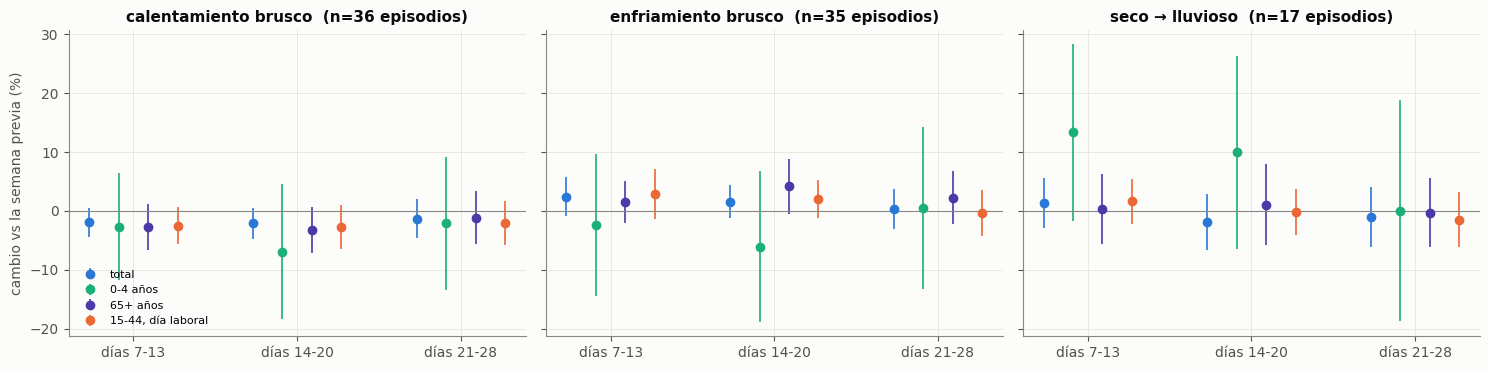

ventana                                     días 7-13    días 14-20  \
cambio               desenlace                                        
calentamiento brusco total                 -1.9 ± 2.5    -2.1 ± 2.6   
                     0-4 años              -2.6 ± 9.2   -6.9 ± 11.4   
                     65+ años              -2.7 ± 3.9    -3.2 ± 3.9   
                     15-44, día laboral    -2.5 ± 3.2    -2.7 ± 3.7   
enfriamiento brusco  total                 +2.4 ± 3.3    +1.6 ± 2.8   
                     0-4 años             -2.3 ± 12.0   -6.1 ± 12.8   
                     65+ años              +1.6 ± 3.6    +4.2 ± 4.7   
                     15-44, día laboral    +2.9 ± 4.3    +2.0 ± 3.2   
seco → lluvioso      total                 +1.3 ± 4.3    -1.9 ± 4.7   
                     0-4 años            +13.4 ± 15.0  +10.0 ± 16.4   
                     65+ años              +0.4 ± 5.9    +1.1 ± 6.9   
                     15-44, día laboral    +1.7 ± 3.9    -0.1 ± 3.9   

ventana                                   días 21-28  episodios  
cambio               desenlace                                   
calentamiento brusco total                -1.3 ± 3.3         36  
                     0-4 años            -2.1 ± 11.3         36  
                     65+ años             -1.1 ± 4.5         36  
                     15-44, día laboral   -2.0 ± 3.7         36  
enfriamiento brusco  total                +0.3 ± 3.5         35  
                     0-4 años            +0.5 ± 13.7         35  
                     65+ años             +2.3 ± 4.5         35  
                     15-44, día laboral   -0.3 ± 3.9         35  
seco → lluvioso      total                -1.0 ± 5.1         17  
                     0-4 años            +0.1 ± 18.8         17  
                     65+ años             -0.3 ± 5.9         17  
                     15-44, día laboral   -1.5 ± 4.6         17

In [11]:
def episodios(senal, sep=28):
    ini, ult = [], None
    for d in senal[senal.fillna(False)].index:
        if ult is None or (d - ult).days >= sep:
            ini.append(d); ult = d
    return [d for d in ini if pd.Timestamp(INI) <= d <= pd.Timestamp(FIN) - pd.Timedelta(days=28)]

EP = {"calentamiento brusco": episodios(calentamiento), "enfriamiento brusco": episodios(enfriamiento),
      "seco → lluvioso": episodios(seco_a_lluvioso)}
salidas = {"total": R.total, "0-4 años": R["0-4"], "65+ años": R["65+"],
           "15-44, día laboral": R["15-44"].where(laboral)}
VENT = {"días 7-13": (7, 13), "días 14-20": (14, 20), "días 21-28": (21, 28)}
filas = []
for ne, fechas in EP.items():
    for ns, serie in salidas.items():
        difs = {k: [] for k in VENT}
        for f in fechas:
            base = serie.loc[f - pd.Timedelta(days=7): f - pd.Timedelta(days=1)].mean()
            for k, (a, b) in VENT.items():
                difs[k].append(serie.loc[f + pd.Timedelta(days=a): f + pd.Timedelta(days=b)].mean() - base)
        for k, v in difs.items():
            v = pd.Series(v).dropna()
            filas.append({"cambio": ne, "desenlace": ns, "ventana": k, "efecto %": pct(v.mean()),
                          "ic": 1.96 * v.std() / np.sqrt(len(v)) * 100, "n": len(v)})
T41 = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
colores = [AZUL, AQUA, VIOLETA, NARANJA]
for ax, (ne, g) in zip(axes, T41.groupby("cambio", sort=False)):
    for j, (ns, h) in enumerate(g.groupby("desenlace", sort=False)):
        x = np.arange(3) + (j - 1.5) * .18
        ax.errorbar(x, h["efecto %"], yerr=h["ic"], fmt="o", color=colores[j], ms=6, lw=1.2, label=ns)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(3), list(VENT)); ax.set_title(f"{ne}  (n={int(g.n.max())} episodios)")
axes[0].set_ylabel("cambio vs la semana previa (%)"); axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
T41.assign(celda=T41.apply(lambda r: f"{r['efecto %']:+.1f} ± {r.ic:.1f}", axis=1)).pivot_table(index=["cambio", "desenlace"], columns="ventana", values="celda", aggfunc="first", sort=False).assign(episodios=T41.groupby(["cambio", "desenlace"], sort=False).n.max())


## Lectura

**Hay una forma coherente con la incubación en los niños, pero el efecto no se distingue de cero.**

| | días 7-13 | días 14-20 | días 21-28 | episodios |
|---|---|---|---|---|
| seco → lluvioso, 0-4 años | +13,4 ± 15,0 | +10,0 ± 16,4 | +0,1 ± 18,8 | 17 |
| enfriamiento, 65+ años | +1,6 ± 3,6 | +4,2 ± 4,7 | +2,3 ± 4,5 | 35 |
| enfriamiento, 15-44 en día laboral | +2,9 ± 4,3 | +2,0 ± 3,2 | −0,3 ± 3,9 | 35 |
| enfriamiento, total | +2,4 ± 3,3 | +1,6 ± 2,8 | +0,3 ± 3,5 | 35 |
| calentamiento, total | −1,9 ± 2,5 | −2,1 ± 2,6 | −1,3 ± 3,3 | 36 |

Tras el paso de seco a lluvioso, los niños de 0 a 4 años suben alrededor de 13 % en la segunda semana y 10 % en la tercera, y el efecto se apaga a la cuarta. Es la forma de una incubación: no pasa nada el mismo día, sube después y se desvanece. Pero con 17 episodios el intervalo cruza el cero en las tres ventanas, de modo que queda como pista y no como hallazgo. Una versión anterior daba +22,0 ± 17,8 % con 13 episodios y un intervalo que no cruzaba el cero; se calculó con un pluviómetro que reportaba cero milímetros durante meses mientras llovía, y esas sequías falsas fabricaban episodios de «seco a lluvioso». Con el clima corregido el efecto baja casi a la mitad y deja de ser significativo.

El enfriamiento sube algo a los mayores y a los adultos en día laboral, y el calentamiento lo baja. Los signos son coherentes en casi todas las ventanas, pero cada intervalo por separado cruza el cero.

Esto es lo que el cuaderno 06 no podía ver: allí se medía el nivel de la semana en una sola ventana semanal. Aquí se mira el cambio, desde la segunda semana y en el grupo que se enferma primero. Que ahora el efecto sea débil no lo refuta; indica que con 17 episodios y este ruido no se puede decidir.

**Límites.**
- Son 36 comparaciones (3 cambios, 4 desenlaces, 3 ventanas): por azar alguna saldría «significativa». Cualquier resultado de los niños hay que confirmarlo con episodios nuevos o fuera de muestra.
- El efecto sobre el total es de ±2 %, pequeño frente al ruido diario (12 %). Para el pronóstico del total estas variables ayudarán poco por sí solas; su valor está en el subgrupo pediátrico y en la serie respiratoria, no en el volumen completo.

**Sensibilidad del resultado de los niños.** La celda que sigue abre el efecto de los días 7-13 episodio por episodio, para ver si lo sostiene un solo caso.

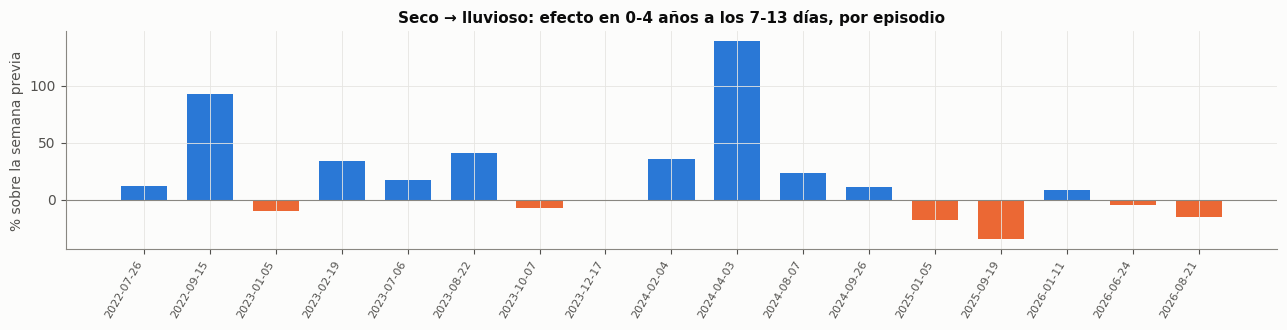

todos los episodios: n = 17: media +13.4 ± 15.6 %, mediana +11.3 %, positivos 11 de 17
sin 2024-04-03:      n = 16: media +8.2 ± 13.0 %, mediana +10.0 %, positivos 10 de 16
episodio máximo: 2024-04-03, +139 %


In [12]:
# Efecto seco -> lluvioso en 0-4 anios, dias 7-13, episodio por episodio (en logaritmo, como en la tabla anterior)
fe = EP["seco → lluvioso"]
s04 = R["0-4"]
lg = pd.Series({f: s04.loc[f + pd.Timedelta(days=7): f + pd.Timedelta(days=13)].mean()
                   - s04.loc[f - pd.Timedelta(days=7): f - pd.Timedelta(days=1)].mean() for f in fe})
efe = pct(lg)
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.bar(range(len(efe)), efe.values, color=[AZUL if v > 0 else NARANJA for v in efe.values], width=.7)
ax.set_xticks(range(len(efe)), [f"{f:%Y-%m-%d}" for f in efe.index], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("% sobre la semana previa")
ax.set_title("Seco → lluvioso: efecto en 0-4 años a los 7-13 días, por episodio")
plt.tight_layout(); plt.show()
def resumen(l):
    n = len(l); se = l.std() / np.sqrt(n)
    return (f"n = {n}: media {pct(l.mean()):+.1f} ± {1.96 * pct(se) :.1f} %, mediana {pct(l.median()):+.1f} %, "
            f"positivos {int((l > 0).sum())} de {n}")
print("todos los episodios:", resumen(lg))
print("sin 2024-04-03:     ", resumen(lg.drop(pd.Timestamp("2024-04-03"))))
print(f"episodio máximo: {efe.idxmax():%Y-%m-%d}, {efe.max():+.0f} %")


**Lectura.** De los 17 episodios, 11 tienen efecto positivo en los niños a los 7-13 días y 6 negativo; la mediana es +11,3 % y la media +13,4 % (± 15,6). El episodio más alto, el 3 de abril de 2024 (+139 %), cae en el mes en que la Supersalud interviene Nueva EPS y Sura sube de nivel (sección 1): no se puede separar del cambio de asegurador. Sin él, quedan 16 episodios con media +8,2 % (± 13,0), mediana +10,0 % y 10 positivos. La dirección es consistente (alrededor de dos de cada tres episodios suben), pero la magnitud es modesta y la media depende de un caso influyente.

## 4.2 Subidas de la IRA en la ciudad, día laboral frente a fin de semana

Se toman las semanas en que la IRA de Manizales sin el SES sube por encima del percentil 80 de su cambio a dos semanas. Si el mecanismo es «me enfermo y voy a urgencias por la incapacidad», el efecto de 1 a 3 semanas después debe ser mayor en día laboral que en fin de semana o festivo. Se muestra con y sin estacionalidad: sin ella, lo que queda es si las subidas de ese año pesan más que la temporada normal.

In [13]:
sem = lambda s: s.resample("W-SAT").mean().rename(lambda i: i - pd.Timedelta(days=6))
estac = lambda s: s - s.groupby(s.index.isocalendar().week.values).transform("mean")
filas = []
for ns, serie in [("total", R.total), ("15-44 años", R["15-44"])]:
    for nd, mask in [("día laboral", laboral), ("fin de semana/festivo", ~laboral)]:
        w = sem(serie.where(mask)).loc["2022-03":"2025-12"]
        for tratamiento, ww in [("con estacionalidad", w), ("sin estacionalidad", estac(w))]:
            prev = subida_sem.reindex(ww.index).fillna(False)
            tras = prev.shift(1, fill_value=False) | prev.shift(2, fill_value=False) | prev.shift(3, fill_value=False)
            a, b = ww[tras], ww[~tras]
            d = a.mean() - b.mean(); e = 1.96 * np.sqrt(a.var() / a.count() + b.var() / b.count())
            filas.append({"desenlace": ns, "día": nd, "tratamiento": tratamiento, "efecto %": round(pct(d), 1),
                          "IC95": f"[{pct(d-e):+.1f}, {pct(d+e):+.1f}]", "semanas tras subida": int(a.count())})
T42 = pd.DataFrame(filas)
print(f"semanas con subida fuerte de IRA (2022-2025): {int(subida_sem.loc['2022':'2025'].sum())}")
None


semanas con subida fuerte de IRA (2022-2025): 42


In [14]:
T42

,desenlace,día,tratamiento,efecto %,IC95,semanas tras subida
0,total,día laboral,con estacionalidad,-0.8,"[-3.0, +1.4]",87
1,total,día laboral,sin estacionalidad,-0.3,"[-1.9, +1.4]",87
2,total,fin de semana/festivo,con estacionalidad,0.5,"[-2.0, +3.0]",87
3,total,fin de semana/festivo,sin estacionalidad,0.6,"[-1.6, +2.8]",87
4,15-44 años,día laboral,con estacionalidad,-1.0,"[-3.3, +1.3]",87
5,15-44 años,día laboral,sin estacionalidad,-0.4,"[-2.2, +1.5]",87
6,15-44 años,fin de semana/festivo,con estacionalidad,-0.3,"[-3.1, +2.7]",87
7,15-44 años,fin de semana/festivo,sin estacionalidad,0.4,"[-2.2, +3.1]",87


## Lectura

**Las subidas de la IRA de la ciudad no se ven en el triage del SES de 1 a 3 semanas después, ni en día laboral ni en fin de semana.** Todos los efectos están entre −1,0 % y +0,6 %, con intervalos de ±2-3 %, y hay 42 semanas de subida (87 semanas en las tres ventanas posteriores).

El mecanismo «me enfermo y voy a urgencias por la incapacidad» no aparece por esta vía. Eso no significa que no exista: hay tres explicaciones que estos datos no distinguen.

- La IRA del SIVIGILA mezcla consulta externa con urgencias, y su subida puede ser de consultas programadas.
- El SES no reporta IRA, de modo que la serie es de otras instituciones y de otra población.
- El efecto existe pero es menor que el ruido del total, que es el 12 % diario.

La vía que sí mostró una forma, aunque débil, es el clima leído como cambio brusco sobre los niños (sección 4.1), no la vigilancia de la ciudad sobre el volumen total.

---
# 5. La red: la caída de Nueva EPS y sus escalones

Si otras instituciones cierran servicios a Nueva EPS, sus afiliados podrían desviarse al SES, y Nueva EPS debería subir respecto de Sura después de cada fecha. Se compara el triage semanal de ambas en 2025-2026 alrededor de dos cierres de otras instituciones, y a continuación se describen los niveles de Nueva EPS por periodos.

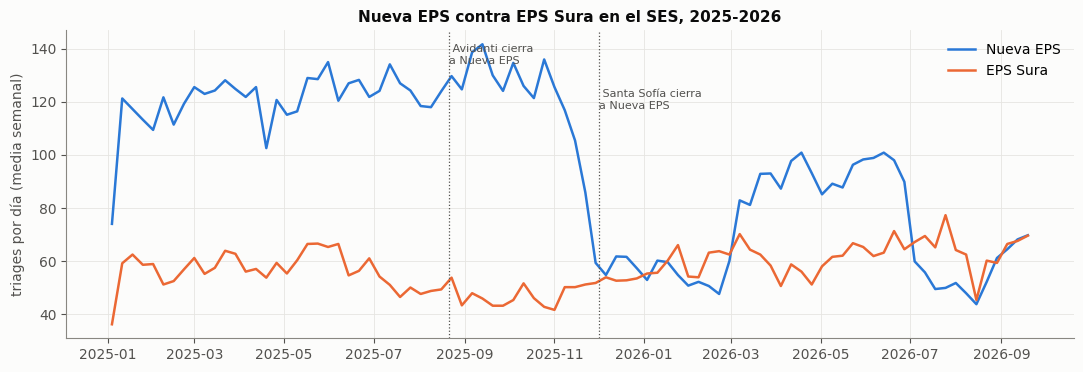

,Nueva EPS %,Sura %,diferencia (Nueva − Sura) %
fecha,,,
2025-08-21,5.8,-8.4,15.5
2025-12-01,-47.2,16.8,-54.8


In [15]:
W5 = S[["nueva_eps", "sura_eps"]].loc["2025-01-01":FIN].resample("W-SAT").sum()
W5 = W5[W5.index <= pd.Timestamp(FIN)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(W5.index, W5.nueva_eps / 7, color=AZUL, lw=1.8, label="Nueva EPS")
ax.plot(W5.index, W5.sura_eps / 7, color=NARANJA, lw=1.8, label="EPS Sura")
filas = []
for i, (f, t) in enumerate([("2025-08-21", "Avidanti cierra\na Nueva EPS"), ("2025-12-01", "Santa Sofía cierra\na Nueva EPS")]):
    f = pd.Timestamp(f); ax.axvline(f, color=TINTA2, ls=":", lw=.9); ax.text(f, W5.max().max() / 7 * (1.0 - .12 * i), " " + t, fontsize=8, color=TINTA2, va="top")
    antes_, despues = W5[(W5.index > f - pd.Timedelta(weeks=8)) & (W5.index <= f)], W5[(W5.index > f) & (W5.index <= f + pd.Timedelta(weeks=8))]
    r = np.log(despues.mean() / antes_.mean())
    filas.append({"fecha": f"{f:%Y-%m-%d}", "Nueva EPS %": round(pct(r.nueva_eps), 1), "Sura %": round(pct(r.sura_eps), 1),
                  "diferencia (Nueva − Sura) %": round(pct(r.nueva_eps - r.sura_eps), 1)})
ax.set_ylabel("triages por día (media semanal)"); ax.set_title("Nueva EPS contra EPS Sura en el SES, 2025-2026"); ax.legend(loc="upper right")
plt.show()
pd.DataFrame(filas).set_index("fecha")


,total,nueva_eps,sura_eps,resto (sin Nueva EPS),días
ene a 13-nov 2025,207.3,123.8,54.1,83.5,317
15-nov 2025 a feb 2026,149.5,58.1,56.5,91.4,106
mar a jun 2026,190.8,92.1,61.7,98.7,122
jul a ago 2026,156.2,51.7,63.1,104.5,62
1 a 20 sep 2026,178.4,66.6,68.3,111.9,20


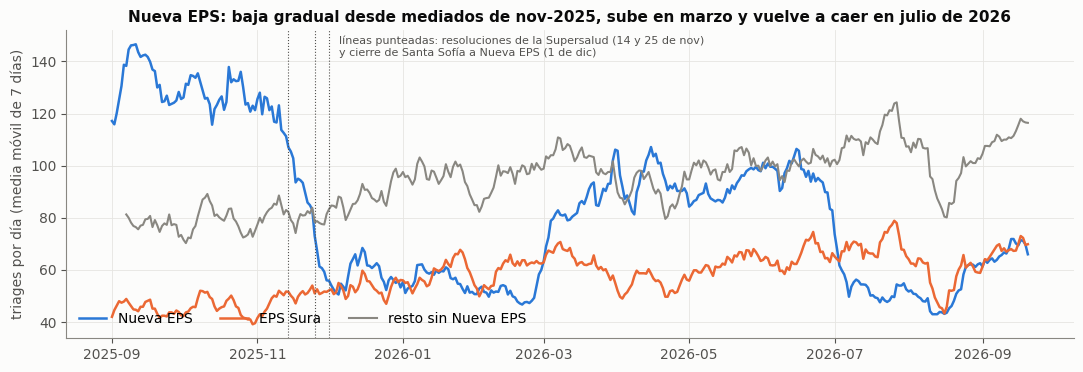

media móvil de 7 días de Nueva EPS: {'10-Nov': 123, '15-Nov': 105, '24-Nov': 83, '30-Nov': 56}
cambio del 1.er al 2.º periodo: Nueva EPS -65.7, resto +7.8, total -28 %


"diferencia Nueva − Sura, 8 sem. después vs 8 antes (%)",08-21,12-01
año,,
2022,11.1,-10.9
2023,0.0,-1.5
2024,11.1,1.7
2025,15.5,-54.8


In [16]:
# Niveles de Nueva EPS por periodo (sin quitar estacionalidad) y el desplome de noviembre de 2025
W = S[["total", "nueva_eps", "sura_eps"]].copy()
W["resto (sin Nueva EPS)"] = W.total - W.nueva_eps
PER = [("ene a 13-nov 2025", "2025-01-01", "2025-11-13"), ("15-nov 2025 a feb 2026", "2025-11-15", "2026-02-28"),
       ("mar a jun 2026", "2026-03-01", "2026-06-30"), ("jul a ago 2026", "2026-07-01", "2026-08-31"),
       ("1 a 20 sep 2026", "2026-09-01", FIN)]
niveles = pd.DataFrame({n: W.loc[a:b].mean() for n, a, b in PER}).T.round(1)
niveles["días"] = [len(W.loc[a:b]) for _, a, b in PER]
display(niveles)

n7 = W[["nueva_eps", "sura_eps"]].rolling(7).mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(n7.loc["2025-09-01":].index, n7.loc["2025-09-01":, "nueva_eps"], color=AZUL, lw=1.8, label="Nueva EPS")
ax.plot(n7.loc["2025-09-01":].index, n7.loc["2025-09-01":, "sura_eps"], color=NARANJA, lw=1.8, label="EPS Sura")
ax.plot(W.loc["2025-09-01":].index, W.loc["2025-09-01":, "resto (sin Nueva EPS)"].rolling(7).mean(), color=MUDO, lw=1.5, label="resto sin Nueva EPS")
for f, t in [("2025-11-14", "resolución\nSupersalud 14-nov"), ("2025-11-25", "resolución\n25-nov"), ("2025-12-01", "Santa Sofía\n1-dic")]:
    ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":")
ax.text(pd.Timestamp("2025-12-05"), 150, "líneas punteadas: resoluciones de la Supersalud (14 y 25 de nov)\ny cierre de Santa Sofía a Nueva EPS (1 de dic)", fontsize=8, color=TINTA2, va="top")
ax.set_ylabel("triages por día (media móvil de 7 días)"); ax.set_title("Nueva EPS: baja gradual desde mediados de nov-2025, sube en marzo y vuelve a caer en julio de 2026")
ax.legend(loc="lower left", ncol=3); plt.show()
print("media móvil de 7 días de Nueva EPS:", {f"{d:%d-%b}": round(n7.nueva_eps.loc[d]) for d in pd.to_datetime(["2025-11-10", "2025-11-15", "2025-11-24", "2025-11-30"])})
(p1, p2) = (W.loc["2025-01-01":"2025-11-13"].mean(), W.loc["2025-11-15":"2026-02-28"].mean())
print(f"cambio del 1.er al 2.º periodo: Nueva EPS {p2.nueva_eps - p1.nueva_eps:+.1f}, resto {p2['resto (sin Nueva EPS)'] - p1['resto (sin Nueva EPS)']:+.1f}, total {100 * (p2.total / p1.total - 1):+.0f} %")

# Control: la misma comparacion de 8 semanas en las mismas fechas de otros anios
W5c = S[["nueva_eps", "sura_eps"]].resample("W-SAT").sum()
filas = []
for y in range(2022, 2026):
    for md in ["08-21", "12-01"]:
        f = pd.Timestamp(f"{y}-{md}")
        a = W5c[(W5c.index > f - pd.Timedelta(weeks=8)) & (W5c.index <= f)]
        d = W5c[(W5c.index > f) & (W5c.index <= f + pd.Timedelta(weeks=8))]
        r = np.log(d.mean() / a.mean())
        filas.append({"año": y, "fecha": md, "Nueva EPS %": round(pct(r.nueva_eps), 1), "Sura %": round(pct(r.sura_eps), 1),
                      "diferencia (Nueva − Sura) %": round(pct(r.nueva_eps - r.sura_eps), 1)})
display(pd.DataFrame(filas).pivot(index="año", columns="fecha", values="diferencia (Nueva − Sura) %").rename_axis(columns="diferencia Nueva − Sura, 8 sem. después vs 8 antes (%)"))


## Lectura

**El hallazgo de mayor tamaño del cuaderno es institucional.**

| Fecha | Nueva EPS | Sura | Diferencia |
|---|---|---|---|
| 2025-08-21 (Avidanti suspende servicios a Nueva EPS) | +5,8 % | −8,4 % | +15,5 % |
| 2025-12-01 (Santa Sofía cierra a Nueva EPS) | −47,2 % | +16,8 % | −54,8 % |

**Los escalones de Nueva EPS.** Con los niveles por periodo (celda anterior), Nueva EPS tiene 123,8 triages por día de enero a mediados de noviembre de 2025, 58,1 de mediados de noviembre de 2025 a febrero de 2026, 92,1 de marzo a junio, 51,7 en julio y agosto y 66,6 en los primeros 20 días de septiembre. Sura se mantiene entre 54 y 68 y el resto de aseguradores sube poco, de modo que el total sigue a Nueva EPS: 207,3, 149,5, 190,8, 156,2 y 178,4.

- El desplome de noviembre de 2025 no es de un día para otro: la media de 7 días de Nueva EPS pasa de unos 123 el 10 de noviembre a 105 el 15, a 83 el 24 y a 56 el 30. Empieza antes del 1 de diciembre, así que no se explica por el cierre de Santa Sofía. Coincide con las resoluciones de la Supersalud sobre Nueva EPS del 14 y el 25 de noviembre de 2025 (cuaderno 18).
- La recuperación de marzo de 2026 y la nueva caída de julio no tienen resolución cercana. Una explicación posible es la contratación entre el SES y la EPS, que no es pública; con estos datos no se puede comprobar.
- La compensación es pequeña: del primer periodo al segundo, Nueva EPS pierde 65,7 triages por día y el resto de aseguradores gana 7,8, de modo que el total baja un 28 %. Esas diferencias son entre periodos de meses distintos del año, sin quitar estacionalidad, y deben leerse como orden de magnitud.
- Los datos de afiliación (cuaderno 18) indican que Nueva EPS perdió 19,5 % de afiliados en Manizales entre julio de 2025 y agosto de 2026 pero 60 % de su triage en el SES, es decir, 50 % menos uso por afiliado. La caída es sobre todo de acceso y no de traslado de afiliados.

**Sobre el cierre de Avidanti.** La diferencia de +15,5 % entre Nueva EPS y Sura a 8 semanas es compatible con un desvío de afiliados, pero la celda de control muestra que en esa misma fecha de otros años la diferencia fue de +11,1 % (2022), 0,0 % (2023) y +11,1 % (2024). La cifra de 2025 está en el rango habitual de esa época del año, de modo que este diseño no puede atribuirla al cierre. El caso de Santa Sofía queda tapado por el desplome que empezó antes (−54,8 % frente a un rango de −10,9 % a +1,7 % en los otros años en la misma fecha).

**Límites.**
- Se necesitan las fechas exactas de suspensión y reanudación de servicios entre el SES y Nueva EPS. Con ellas esta variable pasaría de ser una figura a un predictor conocido por adelantado, porque una suspensión se anuncia. Sin ellas, el estado de Nueva EPS solo se infiere de su propio nivel reciente.
- Los niveles por periodo no quitan la estacionalidad, y la composición estacional de enero-febrero es distinta de la de marzo-junio.
- Lo que explica la caída (barrera de acceso, intervención, quiebra) es una lectura de los datos de afiliación y del contexto institucional, no una medición de este cuaderno.

---
# 6. Conclusiones y límites

| Mecanismo | Reloj | Huella | Qué se vio |
|---|---|---|---|
| Red de salud (Nueva EPS) | escalones | el asegurador | −38 % de Nueva EPS en 2026; desplome gradual desde mediados de noviembre de 2025 y nueva caída en julio de 2026 |
| Feria | 0-5 días (particulares hasta unos 12) | SOAT, otras EPS, particulares | SOAT +37 % frente a +12 % de otros regresos; otras EPS +32 % frente a +11 %; particulares +61 % frente a +29 %; total +7,3 % frente a +2,7 %, que se solapan |
| Eventos sociales | 0-5 días | fines de semana | preceden a 18 de 30 picos, 2 veces la tasa base |
| Seco → lluvioso | 1-2 semanas | 0-4 años | +13,4 ± 15,0 % a 7-13 días (17 episodios); no significativo tras corregir el pluviómetro |
| Enfriamiento / calentamiento | 1-3 semanas | mayores, laboral | ±2-4 %, dirección coherente, cada intervalo cruza el cero |
| Lluvia fuerte | mismo día | madrugada | −4,3 % [−12,1; +4,3], sin efecto distinguible; ningún aumento de tránsito |
| Tránsito de la ciudad | — | SOAT | no se mueve con el SOAT del SES (r = 0,01), salvo en la Feria |
| Subida de IRA en la ciudad | 1-3 semanas | laboral | sin efecto distinguible |

**Lo que se sostiene.** Los factores externos sí dejan huella en el triage cuando se miran en su reloj y en su subgrupo, y no aparecen cuando se promedian sobre el total y todo el año. La red de salud es el factor de mayor magnitud (±40-55 % en el nivel). La Feria deja una huella clara en accidentes y en pacientes de otras aseguradoras, concentrada en una fracción pequeña del volumen. Los efectos de clima son, en cambio, débiles: la pista pediátrica del paso de seco a lluvioso conserva la forma pero no la significación.

**Para el modelo de pronóstico**, en orden de peso: (1) el estado de la relación entre el SES y Nueva EPS, que es la variable de mayor efecto; (2) la persistencia del residuo, con autocorrelación semanal de +0,62 (medida en el cuaderno 06); (3) la Feria y los eventos grandes, con su huella de 0 a 5 días; (4) las transiciones de clima a 1-2 semanas, para la parte pediátrica, con peso bajo.

**Límites del análisis.**
- La Feria tiene 5 episodios, uno de ellos en 2020, y cae siempre al regreso de las vacaciones de fin de año; la parte atribuible a Año Nuevo no se puede separar con estos datos. El mecanismo de que quien llega lo hace porque otras instituciones están saturadas o por remisiones no está probado, porque no se dispone de las remisiones diarias del CRUE.
- Los efectos lentos de clima se miden con 17 a 36 episodios y 36 comparaciones, sin corrección por comparaciones múltiples; ninguno se ha confirmado fuera de muestra.
- Los niveles de Nueva EPS no distinguen entre decisiones de contratación, barreras de acceso e intervención, porque no se dispone de las fechas de suspensión de servicios.
- Todos los efectos se expresan sobre un control de calendario y de año; un efecto que coincida con una fecha fija del calendario (como la Feria con Año Nuevo) no se separa del control.
